# 5. Training data and the final model

Each public corpus was used alone (M1–M4) and mixed (M5, 10 h of each), then with every hour of the four corpora
(M5-full, 156 h) and with 144 h of OpenSLR 53 read speech added (M5-300, ~300 h). Same recipe every time.

In [1]:
from nbutil import *
import pandas as pd

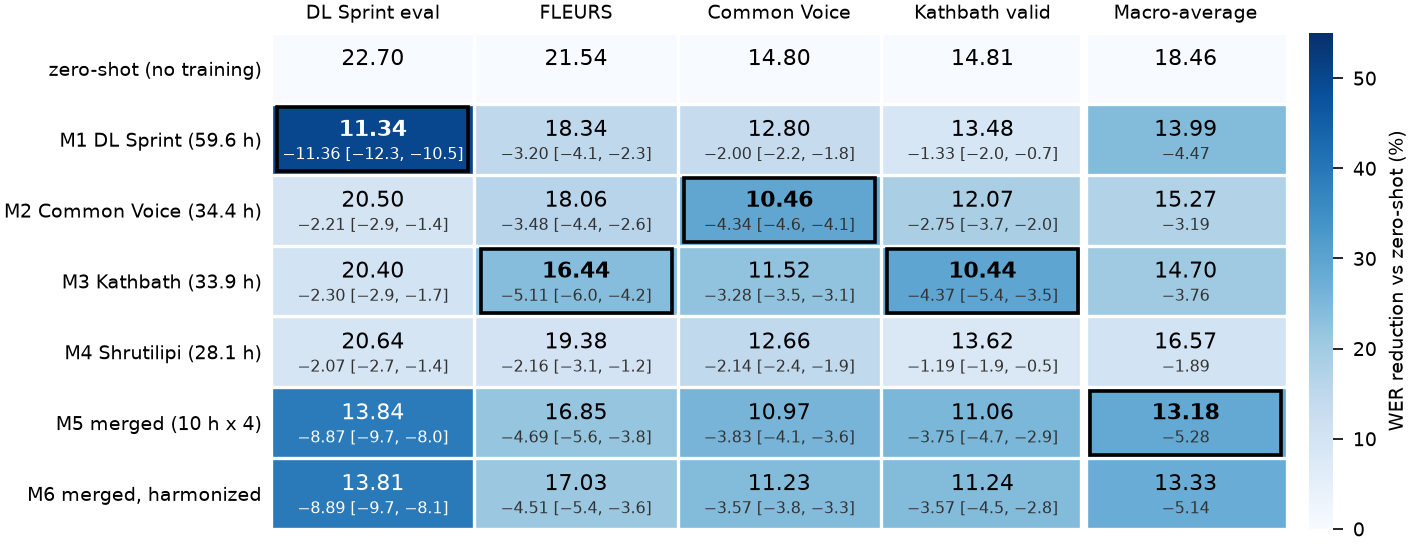

In [2]:
figure("f13_matrix_heatmap")

In [3]:
K = "results/kaggle/finetuned/{}/"
t = wer_table({"zero-shot": ZERO_SHOT, "M1: DL Sprint (60 h)": "results/modal/finetuned/{}/m1_full",
               "M5: 10 h x 4": K + "m5_merged_t4", "M5-full (156 h)": K + "m5_full_t4", "M5-300 (300 h)": K + "m5_300_t4",
               "final: 0.25 M1 + 0.75 M5-300": FINAL})
t["average"] = t.mean(axis=1).round(2); t

,DL Sprint eval,FLEURS,Common Voice,Kathbath,average
zero-shot,22.70,21.54,14.80,14.81,18.46
M1: DL Sprint (60 h),11.34,18.34,12.80,13.48,13.99
M5: 10 h x 4,13.84,16.85,10.97,11.06,13.18
M5-full (156 h),11.50,16.23,10.35,10.07,12.04
M5-300 (300 h),11.49,15.35,10.21,10.07,11.78
final: 0.25 M1 + 0.75 M5-300,11.18,15.60,10.13,10.28,11.80


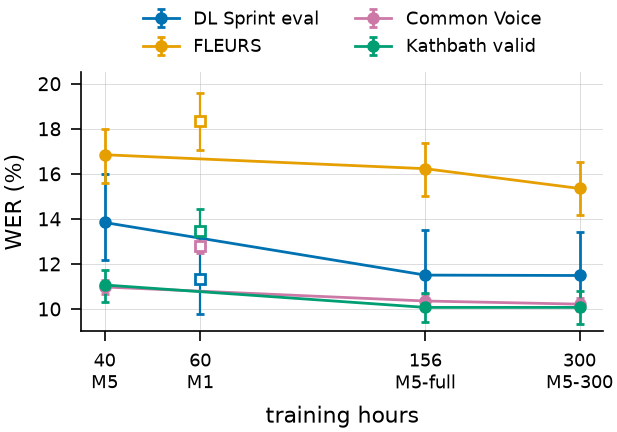

In [4]:
figure("f16_data_scale", 450)

## Choosing the final model
Weight averages of models from the same starting point cost nothing at inference. The rule, fixed before any test
score: lowest average WER over three development sets, adopted only if it beats M5-300 alone.

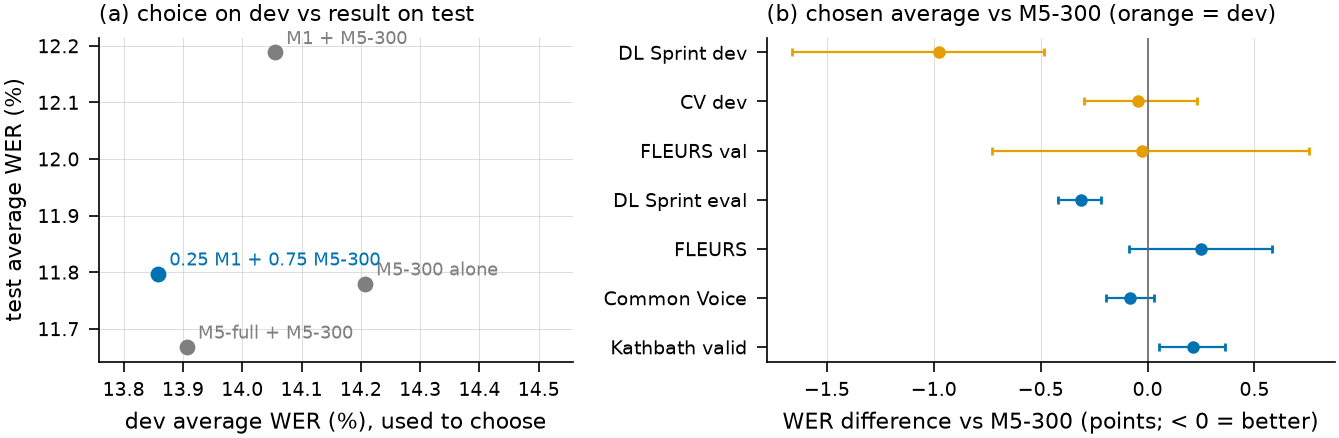

,panel,candidate,dev_avg,test_avg,set,diff,lo,hi,split
0,a,M5-300 alone,14.207078,11.779453,NaN,NaN,NaN,NaN,NaN
1,a,M5-full + M5-300,13.906686,11.667787,NaN,NaN,NaN,NaN,NaN
2,a,M1 + M5-300,14.055413,12.188346,NaN,NaN,NaN,NaN,NaN
3,a,0.25 M1 + 0.75 M5-300,13.858310,11.797092,NaN,NaN,NaN,NaN,NaN


In [5]:
figure("f15_weight_averaging"); figure_data("f15_weight_averaging").query("panel == 'a'")

## Whole recordings
The 22 raw evaluation recordings, cut by voice detection only (no reference-guided cuts), texts joined.

In [6]:
rows = {}
for run, label in [("base_t4", "zero-shot"), ("m1_full_t4", "M1"), ("m5_full_t4", "M5-full"), ("m5_300_t4", "M5-300")]:
    m = load(f"results/kaggle/longform/{run}/metrics.json")
    rows[label] = {"WER": round(100 * m["wer"], 2), "95% CI": f"[{100 * m['wer_ci95'][0]:.2f}, {100 * m['wer_ci95'][1]:.2f}]",
                   "recordings": m["recordings"], "hours": m["audio_hours"], "real-time factor": m["rtf"]}
pd.DataFrame(rows).T

,WER,95% CI,recordings,hours,real-time factor
zero-shot,26.11,"[22.89, 29.63]",22,20.415,0.0936
M1,14.55,"[11.88, 17.70]",22,20.415,0.0907
M5-full,14.62,"[11.89, 17.76]",22,20.415,0.089
M5-300,14.21,"[11.59, 17.25]",22,20.415,0.0895


In [7]:
record("results/kaggle/finetuned/splits_fa-eval/soup_m1_full+m5_300+m5_300+m5_300_t4/run_info.json")

**Run record** `results/kaggle/finetuned/splits_fa-eval/soup_m1_full+m5_300+m5_300+m5_300_t4/run_info.json`  
`python3 /tmp/code/pipeline/eval_zero_shot.py --batch_size 8 --manifest data/splits_fa/eval.csv --model soups/m1_full+m5_300+m5_300+m5_300 --name soup_m1_full+m5_300+m5_300+m5_300_t4 --out_dir results/finetuned`  
commit `` · started 2026-10-21T15:38:33 · 2290.2 s · torch 2.11.0+cu128, transformers 5.15.0, GPU Tesla T4

**Next:** how the final model compares with every other open Bangla model: notebook 6.